# Additional research · ensembles, student capacity and sensor outages

The first cells show the saved extension experiments. These are separate from the original official comparison. The optional reproduction cell uses Drive and writes new runs to a dedicated research folder.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

repo = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "research_extensions").is_dir() and (p / "spikedistill").is_dir()), None)
if repo is None:
    repo = Path("/content/ML3103-research")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/abhav-arora/ML3103-project.git", str(repo)], check=True)
results = repo / "research_extensions/results"
print("Research extension source and saved evidence ready.")

Research extension source and saved evidence ready.


## 1. Do frozen student ensembles reduce prediction error?

The saved ensemble uses three full students from the matched ablation experiment. Equal averaging has fixed weights. Validation weighting uses inverse capped validation MSE. The single reference is chosen by validation MSE. Each subset produces one ensemble from three members, so the table has one score per method and subset.

model,equal_ensemble,validation_best_single,validation_weighted_ensemble
subset,,,
FD001,16.014,15.970,15.899
FD002,28.879,29.646,28.886
FD003,19.033,20.365,19.060
FD004,28.130,28.652,28.128


,subset,model,cmapss_score,parameters
0,FD001,equal_ensemble,476.34,10227
1,FD001,validation_weighted_ensemble,484.14,10227
2,FD001,validation_best_single,689.19,3409
3,FD002,equal_ensemble,17081.62,11091
4,FD002,validation_weighted_ensemble,17165.44,11091
5,FD002,validation_best_single,18831.37,3697
6,FD003,equal_ensemble,1278.26,10371
7,FD003,validation_weighted_ensemble,1298.17,10371
8,FD003,validation_best_single,1805.71,3457
9,FD004,equal_ensemble,6158.91,11091


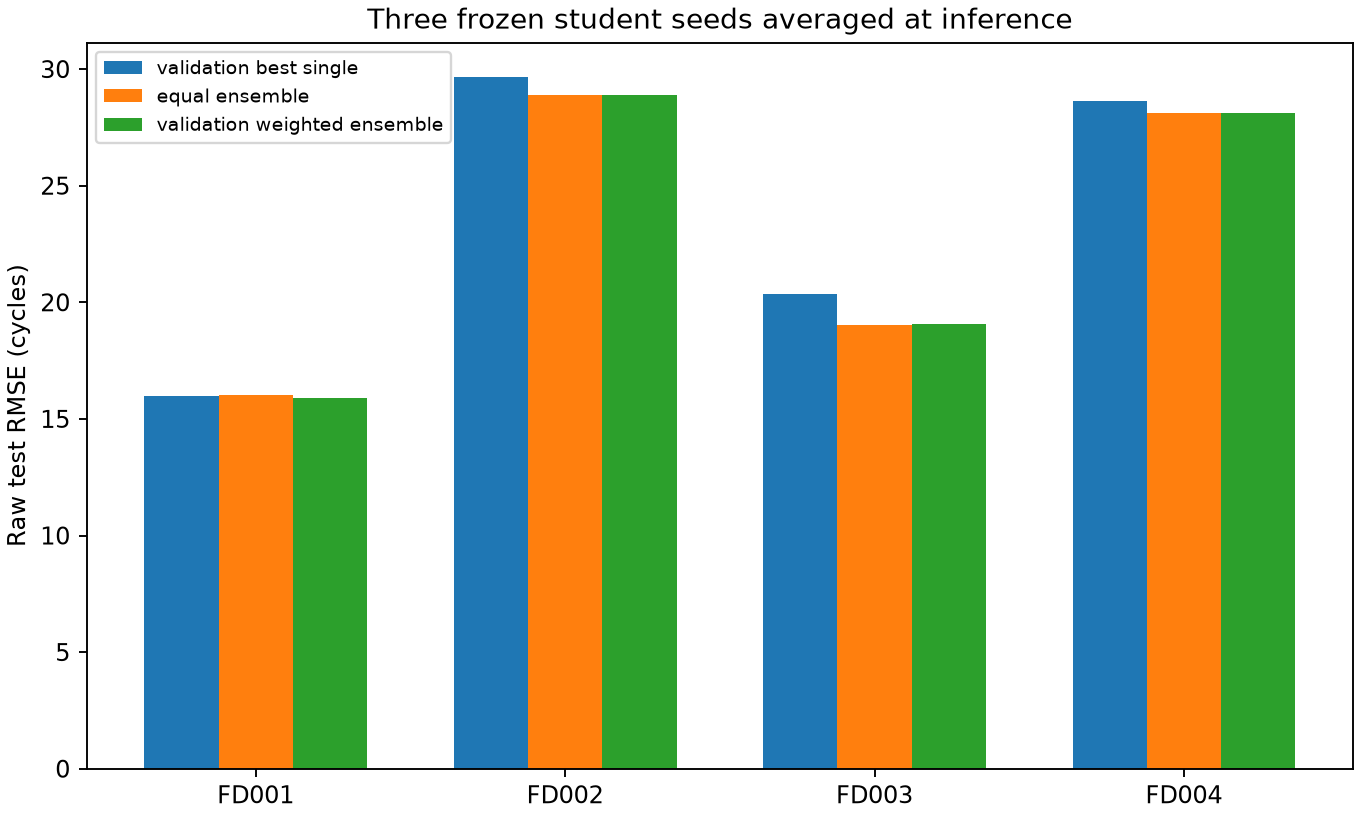

In [2]:
ensemble = pd.read_csv(results / "ensemble_summary.csv")
display(ensemble.pivot(index="subset", columns="model", values="RMSE").round(3))
display(ensemble[["subset", "model", "cmapss_score", "parameters"]].round(2))
display(Image(filename=str(results / "ensemble_comparison.png"), width=740))

## 2. How many spiking neurons does the student need?

The first sweep trains widths 16, 32, 48 and 64 on FD001 at seed 42. All use the same 30-epoch budget and teacher. The selected checkpoint in each run minimizes capped validation RMSE. This first sweep is exploratory. The optional GPU sweep below defaults to all four subsets and three seeds.

,subset,seed,width,parameters,selected_epoch,validation_RMSE,RMSE,cmapss_score
0,FD001,42,16,625,24,17.230,17.750,641.239
1,FD001,42,32,1761,28,14.787,17.302,527.114
2,FD001,42,48,3409,27,14.480,15.970,689.188
3,FD001,42,64,5569,14,17.439,18.322,735.218


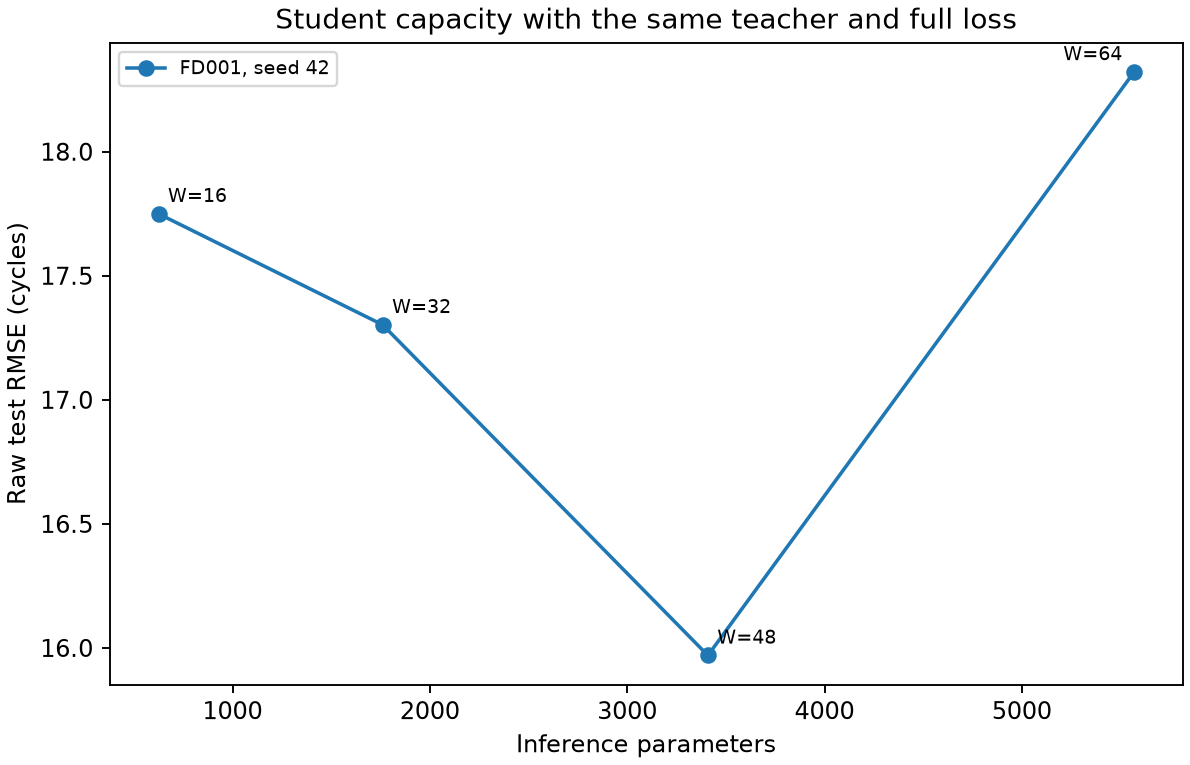

In [3]:
capacity = pd.read_csv(results / "capacity_summary.csv")
display(capacity[["subset", "seed", "width", "parameters", "selected_epoch",
                  "validation_RMSE", "RMSE", "cmapss_score"]].round(3))
display(Image(filename=str(results / "student_capacity.png"), width=700))

## 3. What happens when one sensor is unavailable?

Replace one sensor trace with its standardized training mean and preserve all other inputs. Compare the original teacher and original full student, seed 42. Review both the change from clean RMSE and the absolute accuracy. This is a fixed simulated outage, repeated for every retained sensor.

,model,missing_sensor,RMSE,delta_RMSE,cmapss_score,delta_cmapss_score
0,teacher,clean,15.729,0.000,490.846,0.000
2,student,clean,17.548,0.000,536.618,0.000
4,teacher,sensor_02,17.674,1.945,657.345,166.499
6,student,sensor_02,18.991,1.443,936.107,399.490
8,teacher,sensor_03,16.005,0.276,503.398,12.552
10,student,sensor_03,18.338,0.790,644.992,108.374
12,teacher,sensor_04,16.410,0.681,578.061,87.215
14,student,sensor_04,18.823,1.275,625.664,89.046
16,teacher,sensor_06,15.602,-0.127,453.408,-37.438
18,student,sensor_06,17.224,-0.324,481.995,-54.623


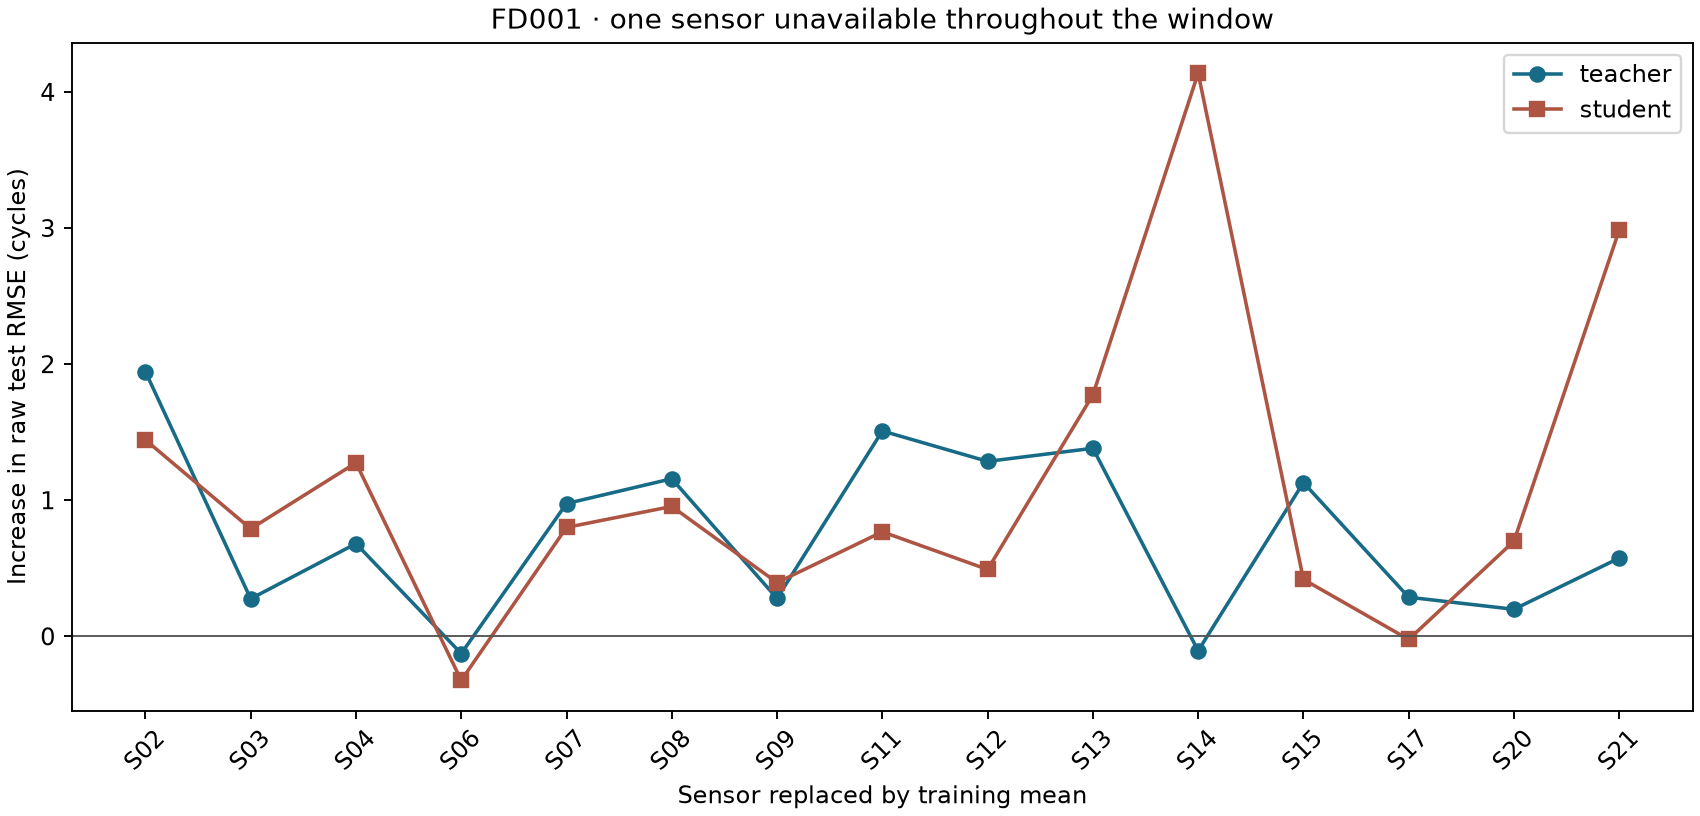

In [4]:
outages = pd.read_csv(results / "sensor_outage/FD001/seed_42/sensor_outage.csv")
display(outages.loc[outages["target"].eq("raw"),
                   ["model", "missing_sensor", "RMSE", "delta_RMSE",
                    "cmapss_score", "delta_cmapss_score"]].round(3))
display(Image(filename=str(results / "sensor_outage/FD001/seed_42/sensor_outage.png"), width=760))

## Optional reproduction

Set the flags below to select experiments. Weight fitting uses validation predictions before the test phase. Capacity training saves checkpoints every epoch. Use a fresh output name when changing the runtime or protocol.

In [5]:
RUN_ENSEMBLES = False
RUN_CAPACITY = False
RUN_OUTAGES = False

if RUN_ENSEMBLES or RUN_CAPACITY or RUN_OUTAGES:
    from google.colab import drive
    import torch
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/ML projec/SpikeDistill-RUL")
    data = project / "artifacts/data"
    baselines = project / "colab_runs/baselines_v1"
    students = project / "colab_runs/spikedistill_v1"
    output = project / "colab_runs/research_extensions/reproduction_v1"
    subsets = ["FD001", "FD002", "FD003", "FD004"]
    seeds = [42, 43, 44]
    device = "cuda" if torch.cuda.is_available() else "cpu"

    def run(module, *args):
        subprocess.run([sys.executable, "-u", "-m", module, *map(str, args)], cwd=repo, check=True)

    if RUN_ENSEMBLES:
        # This reproduction uses original Colab students. The saved local table
        # above uses the ablation controls, which are different trained models.
        for subset in subsets:
            members = [students / subset / f"seed_{seed}" / "spikedistill" for seed in seeds]
            for phase in ("fit", "test"):
                run("research_extensions.ensemble.run", "--members", *members,
                    "--output", output / "seed_ensemble" / subset, "--phase", phase)
    if RUN_CAPACITY:
        if device != "cuda":
            raise RuntimeError("Choose a Colab GPU for the full capacity sweep.")
        for phase in ("train", "test"):
            run("research_extensions.student_capacity.run", "--data-root", data,
                "--baselines", baselines, "--output", output / "student_capacity",
                "--subsets", *subsets, "--seeds", *seeds, "--widths", 16, 32, 48, 64,
                "--epochs", 30, "--device", device, "--verify-prepared-predictions", "--phase", phase)
    if RUN_OUTAGES:
        run("research_extensions.robustness.run", "--data-root", data, "--baselines", baselines,
            "--students", students, "--output", output / "sensor_outage", "--subsets", *subsets,
            "--device", device, "--verify-prepared-predictions")
    run("research_extensions.summarize", "--results", output)